# Commute emissions by mode: New York and Houston

The commuting flows of LODES between census tracts, routed from the housing-weighted home point
to the jobs-weighted work point of 05.7 by transit, car, bicycle, e-bike and on foot, with the
life-cycle CO₂e of each commute attached by cafein. This notebook is written to be rerun for
another city without exploration: every choice sits in the parameter block of step 1, the
factors in force are printed in step 2, and the routing and the commute table follow from them.
The exploratory work behind the choices is in 05.3 to 05.8.

| Step | What we do |
|---|---|
| 1. Parameters | The areas, the routing and emission settings, with their source and what to replace for US-specific factors |
| 2. Factors in force | The per-mode factor table cafein will apply, components and totals |
| 3. Routing with emissions | One cost matrix per area and mode, home points to work points, streamed to scratch |
| 4. Commute table | Every commuting flow with its minutes, distance and grams per mode, saved as one long table per area, with the worker-weighted summary |
| 5. Distribution | The worker-weighted distribution of one-way grams per mode |
| 6. Maps | Weekly commuting CO₂e by home tract, New York beside Houston, one figure per mode in the style of the carbon-budgets paper, saved as PNG |

**Inputs per area**, all produced upstream: the kept tracts and the tract flows of 05.2 or 05.2.1,
the snapped home and work points of 05.7, the street network artifact of 05.3 or 05.3.1 and the
transit network artifact of the same notebook. **To add a city**, run 05.1, 05.2, 05.3 and 05.7
for it, add an entry to `AREAS` and run this notebook; nothing else changes.

In [1]:
import json
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cafein
from cafein import StreetNetwork, TransportNetwork, TravelCostMatrix
from cafein._streaming import read_shards
from cafein.emissions import default_factors, street_factor, street_factors, vehicle_class_factors

print("cafein", cafein.__version__)

cafein 0.31.0


## 1. Parameters

The only cell to edit for another city or another factor set. Each entry carries its source and,
beside it, what to replace to make the factor specific to the United States. The emission
factors are cafein's shipped life-cycle values, the International Transport Forum LCA tool
calibrated to the Finnish electricity mix (Dey, Marín-Flores and Tenkanen 2026), so they are a
placeholder for US fleets and grids; the table says where each US value would come from.

In [2]:
YEAR = 2023
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

# One entry per area: the results folder of 05.1 to 05.7, the street and transit artifacts of 05.3,
# and the departure routed in 05.3. Add an area here to run it.
AREAS = {
    "New York": {"folder": RESULTS / "new-york", "streets": Path("../networks/new-york-streets.cafein"),
                 "transit": RESULTS / "new-york" / "new-york-transit.cafein", "departure": "2026-11-10 08:30"},
    "Houston": {"folder": RESULTS / "houston", "streets": RESULTS / "houston" / "houston-streets.cafein",
                "transit": RESULTS / "houston" / "houston-transit.cafein", "departure": "2026-11-10 08:30"},
    "Chicago": {"folder": RESULTS / "chicago", "streets": RESULTS / "chicago" / "chicago-streets.cafein", "transit": RESULTS / "chicago" / "chicago-transit.cafein", "departure": "2026-11-10 08:30"},
    "Seattle": {"folder": RESULTS / "seattle", "streets": RESULTS / "seattle" / "seattle-streets.cafein", "transit": RESULTS / "seattle" / "seattle-transit.cafein", "departure": "2026-11-10 08:30"},
    "Phoenix": {"folder": RESULTS / "phoenix", "streets": RESULTS / "phoenix" / "phoenix-streets.cafein", "transit": RESULTS / "phoenix" / "phoenix-transit.cafein", "departure": "2026-11-10 08:30"},
}

PARAMETERS = {
    # Transit routing.
    "access_egress_walk_min": 30,         # the walk allowed from the home to the first stop and from the last stop to the work
    "max_rides": 8,                       # cafein default
    "walking_speed_kmph": 3.6,            # cafein default, on the street network and the connectors
    # Street routing.
    "car_profile": "rush",                # intersection-delay model at the morning peak
    "car_parking": False,                 # no parking search time, as in 05.3
    "car_vehicle_class": "ICE",           # baseline powertrain
    "car_occupancy": 1,                   # cafein's car factor is per vehicle-km on the driver-only basis; 1 leaves it untouched
    "car_bev_scenario": True,             # a BEV column derived from the driven distance, as in the carbon-budgets paper
    "bicycle_speed_kmph": 15.3,           # Schleinitz et al. (2017) mean trip speed, cafein default; no elevation model
    "e_bike_speed_kmph": 17.4,            # the same source for pedelecs, as in 05.3.1
    "max_street_time_min": 120,           # cafein default cap of a street route
    # Emissions.
    "components": ["vehicle", "fuel", "infrastructure", "operations"],   # full life cycle
    "walk_g_per_km": 56.0,                # dietary emissions of walking, the carbon-budgets paper's convention; applied to the walk mode and to the walking legs of transit
    "trolleybus_as_electric_bus": True,   # route type 11 has no shipped row; it takes the electric-bus values
    # Reporting.
    "commutes_per_week": 4,               # the paper's weekly routine: four return commutes
    "output_time_units": "seconds",
}

# What each parameter rests on, and what to change for United States specific values.
parameter_table = pd.DataFrame([
    ("flows", f"LODES {YEAR} JT01 primary jobs, tract to tract, kept tracts of 05.2", "05.1, 05.2", "none; LODES is the US source"),
    ("routing points", "housing-weighted home point, jobs-weighted work point, empty-block medoid rule", "05.7, validated in 05.8", "none"),
    ("departure", "Tuesday 08:30 within every feed's validity", "05.3", "none; pick a date the feeds cover"),
    ("access and egress walk", f"{PARAMETERS['access_egress_walk_min']} min at each end (cafein default 120)", "decision of 2026-11-17, sensitivity in 05.8 step 3", "none"),
    ("transfer footpaths", "20 min stop to stop, fixed at network build", "cafein default, 05.3", "none"),
    ("walking speed", f"{PARAMETERS['walking_speed_kmph']} km/h", "cafein default (r5py)", "none"),
    ("car routing", f"{PARAMETERS['car_profile']} profile with intersection delays, no parking time, {PARAMETERS['max_street_time_min']} min cap", "05.3", "none; speed limits already follow US defaults"),
    ("car factor", f"{PARAMETERS['car_vehicle_class']}, per vehicle-km, occupancy {PARAMETERS['car_occupancy']}", "cafein street_factors: ITF LCA, GEMMAT Table 4", "fuel component from EPA Automotive Trends real-world CO2 of the US light-duty fleet; vehicle and infrastructure from the ITF tool at US values; occupancy from the NHTS commute trips"),
    ("car BEV scenario", "BEV factor per vehicle-km applied to the driven distance", "cafein vehicle_class_factors; the paper's 70/162 rescaling", "electricity from the eGRID subregion of each metro (NYCW/NYUP for New York, ERCT for Houston)"),
    ("bicycle factor", "conventional, per person-km, dietary term included", "cafein street_factors: ITF Good to Go, Finland 2020 mix", "optional: US diet-specific dietary term"),
    ("e-bike factor", "e-bike class of the bicycle mode, charging at the Finnish mix", "cafein street_factors", "charging electricity at the eGRID subregion"),
    ("walking", f"{PARAMETERS['walk_g_per_km']:.0f} g per km, dietary, walk mode and transit walking legs", "carbon-budgets paper, 02_routing_and_emissions", "optional: US diet-specific dietary term"),
    ("bus", "ICE bus per passenger-km, route type 3", "cafein default_factors, GEMMAT Table 5", "NTD energy and passenger-miles per agency and mode; electric and CNG fleets per agency"),
    ("tram, metro, rail", "one urban-train value per passenger-km, route types 0 to 2", "cafein default_factors", "NTD per agency and mode; diesel commuter rail (LIRR diesel branches, NJ Transit, Metro-North) separately; electricity at the eGRID subregion"),
    ("ferry", "Suomenlinna-derived value per passenger-km, route type 4", "cafein default_factors", "NTD ferry energy per passenger-mile (Staten Island Ferry, NYC Ferry, NY Waterway)"),
    ("trolleybus", "electric-bus values, route type 11 (one route, The Woodlands)", "decision of 2026-11-17", "NTD trolleybus per agency"),
    ("components", ", ".join(PARAMETERS["components"]), "full life cycle, as the carbon-budgets paper", "none"),
    ("weekly figure", f"{PARAMETERS['commutes_per_week']} return commutes per week", "the paper's decent-mobility routine", "none"),
], columns=["parameter", "value used", "source", "to make it US-specific"]).set_index("parameter")
pd.set_option("display.max_colwidth", None)
parameter_table

,value used,source,to make it US-specific
parameter,,,
flows,"LODES 2023 JT01 primary jobs, tract to tract, kept tracts of 05.2","05.1, 05.2",none; LODES is the US source
routing points,"housing-weighted home point, jobs-weighted work point, empty-block medoid rule","05.7, validated in 05.8",none
departure,Tuesday 08:30 within every feed's validity,05.3,none; pick a date the feeds cover
access and egress walk,30 min at each end (cafein default 120),"decision of 2026-11-17, sensitivity in 05.8 step 3",none
transfer footpaths,"20 min stop to stop, fixed at network build","cafein default, 05.3",none
walking speed,3.6 km/h,cafein default (r5py),none
car routing,"rush profile with intersection delays, no parking time, 120 min cap",05.3,none; speed limits already follow US defaults
car factor,"ICE, per vehicle-km, occupancy 1","cafein street_factors: ITF LCA, GEMMAT Table 4",fuel component from EPA Automotive Trends real-world CO2 of the US light-duty fleet; vehicle and infrastructure from the ITF tool at US values; occupancy from the NHTS commute trips
car BEV scenario,BEV factor per vehicle-km applied to the driven distance,cafein vehicle_class_factors; the paper's 70/162 rescaling,"electricity from the eGRID subregion of each metro (NYCW/NYUP for New York, ERCT for Houston)"


## 2. Emission factors in force

The factor each mode will carry, in g CO₂e per kilometre, as cafein resolves them: the street
rows from `street_factors`, the transit rows from `default_factors` plus the rows layered on in
this notebook. The car rows are per vehicle-km and are divided by the occupancy above; every
other row is per person-km. The walking row is this notebook's addition, applied after routing.

In [3]:
components = PARAMETERS["components"]

street = street_factors().set_index(["street_mode", "vehicle_class", "service_model"])
street = street.loc[[("walk", "on_foot", "private"), ("bicycle", "conventional", "private"), ("bicycle", "e_bike", "private"),
                     ("car", PARAMETERS["car_vehicle_class"], "private"), ("car", "BEV", "private")]].reset_index()
street["mode"] = ["walk", "bicycle", "e_bike", f"car ({PARAMETERS['car_vehicle_class']})", "car (BEV scenario)"]
street.loc[street["mode"] == "walk", "fuel"] = PARAMETERS["walk_g_per_km"]
street["total"] = street[components].sum(axis=1)
street["per person-km at the occupancy used"] = np.where(street["basis"] == "vehicle_km", street["total"] / PARAMETERS["car_occupancy"], street["total"])
print("street modes, g CO2e per km:")
display(street.set_index("mode")[components + ["basis", "total", "per person-km at the occupancy used"]].round(1))

# Transit: the shipped rows by GTFS route type, plus the trolleybus row.
extra_rows = []
if PARAMETERS["trolleybus_as_electric_bus"]:
    extra_rows.append({"route_type": 11, **vehicle_class_factors().loc["bus-BEV"].to_dict()})
TRANSIT_FACTORS = pd.DataFrame(extra_rows) if extra_rows else None
transit = pd.concat([default_factors(), pd.DataFrame(extra_rows)], ignore_index=True)
transit["mode"] = transit["route_type"].map({0: "tram, light rail", 1: "subway, metro", 2: "rail", 3: "bus", 4: "ferry", 11: "trolleybus"})
transit["total"] = transit[components].sum(axis=1)
print("transit, g CO2e per passenger-km by GTFS route type:")
display(transit.set_index(["route_type", "mode"])[components + ["total"]].round(1))

WALK_G_PER_M = PARAMETERS["walk_g_per_km"] / 1000
CAR_BEV_G_PER_M = street_factor("car", vehicle_class="BEV", components=components) / PARAMETERS["car_occupancy"] / 1000
print(f"BEV scenario: {CAR_BEV_G_PER_M * 1000:.0f} g per person-km against {street_factor('car', vehicle_class=PARAMETERS['car_vehicle_class'], components=components) / PARAMETERS['car_occupancy']:.0f} for the baseline")

street modes, g CO2e per km:


,vehicle,fuel,infrastructure,operations,basis,total,per person-km at the occupancy used
mode,,,,,,,
walk,0.0,56.0,0.0,0.0,passenger_km,56.0,56.0
bicycle,7.0,21.0,9.0,0.0,passenger_km,37.0,37.0
e_bike,13.0,3.0,9.0,0.0,passenger_km,25.0,25.0
car (ICE),24.0,126.0,12.0,0.0,vehicle_km,162.0,162.0
car (BEV scenario),42.0,16.0,12.0,0.0,vehicle_km,70.0,70.0


transit, g CO2e per passenger-km by GTFS route type:


,,vehicle,fuel,infrastructure,operations,total
route_type,mode,,,,,
3,bus,8.0,72.0,4.0,8.0,92.0
0,"tram, light rail",2.0,12.0,11.0,0.0,25.0
1,"subway, metro",2.0,12.0,11.0,0.0,25.0
2,rail,2.0,12.0,11.0,0.0,25.0
4,ferry,6.0,327.0,0.0,0.0,333.0
11,trolleybus,14.0,10.0,4.0,1.0,29.0


BEV scenario: 70 g per person-km against 162 for the baseline


## 3. Routing with emissions

One cost matrix per area and mode, from the snapped home points to the snapped work points of
05.7, streamed to `matrices-emissions/<mode>` in the area's folder. A completed folder is
skipped and a partial one resumed, so a rerun only routes what is missing; a changed parameter
needs a fresh folder. Transit carries the emissions of the ridden legs and the walking metres;
the street modes carry the network distance and the emissions at the mode's factor.

In [4]:
def matrix_complete(path):
    # True when a streamed matrix folder has every shard completed.
    manifest = Path(path) / "manifest.json"
    if not manifest.is_file():
        return False
    shards = json.loads(manifest.read_text())["shards"]
    return bool(shards) and all(shard["completed"] for shard in shards)


STREET_QUERIES = {
    "car": {"transport_mode": "car", "intersection_delays": True, "profile": PARAMETERS["car_profile"], "parking": PARAMETERS["car_parking"],
            "vehicle_class": PARAMETERS["car_vehicle_class"], "occupancy": PARAMETERS["car_occupancy"]},
    "bicycle": {"transport_mode": "bicycle", "speeds": {"bicycle": PARAMETERS["bicycle_speed_kmph"]}},
    "e_bike": {"transport_mode": "e_bike", "speeds": {"e_bike": PARAMETERS["e_bike_speed_kmph"]}},
    "walk": {"transport_mode": "walk", "speeds": {"walk": PARAMETERS["walking_speed_kmph"]}},
}
MODES = ["transit"] + list(STREET_QUERIES)

timings = []
for area, spec in AREAS.items():
    origins = gpd.read_parquet(spec["folder"] / f"tract-points-home-snapped-{YEAR}.parquet")
    destinations = gpd.read_parquet(spec["folder"] / f"tract-points-work-snapped-{YEAR}.parquet")
    matrices = spec["folder"] / "matrices-emissions"
    matrices.mkdir(exist_ok=True)
    print(f"{area}: {len(origins):,} home points, {len(destinations):,} work points")

    output = matrices / "transit"
    if matrix_complete(output):
        print(f"  transit  complete -> {output}")
    else:
        started = time.time()
        network = TransportNetwork.load(spec["transit"])
        TravelCostMatrix.to_parquet(network, origins, destinations, departure=spec["departure"], max_rides=PARAMETERS["max_rides"],
                                    max_walking_time=PARAMETERS["access_egress_walk_min"], speeds={"walk": PARAMETERS["walking_speed_kmph"]},
                                    factors=TRANSIT_FACTORS, components=components, output_time_units=PARAMETERS["output_time_units"],
                                    output=output, resume=output.exists())
        timings.append({"area": area, "mode": "transit", "seconds": time.time() - started})
        print(f"  transit  {time.time() - started:6.0f} s -> {output}")
        del network

    streets = None
    for mode, query in STREET_QUERIES.items():
        output = matrices / mode
        if matrix_complete(output):
            print(f"  {mode:8} complete -> {output}")
            continue
        if streets is None:
            streets = StreetNetwork.load(spec["streets"])
        started = time.time()
        TravelCostMatrix.to_parquet(streets, origins, destinations, max_street_time=PARAMETERS["max_street_time_min"], components=components,
                                    output_time_units=PARAMETERS["output_time_units"], output=output, resume=output.exists(), **query)
        timings.append({"area": area, "mode": mode, "seconds": time.time() - started})
        print(f"  {mode:8} {time.time() - started:6.0f} s -> {output}")
    del streets

pd.DataFrame(timings).round(0) if timings else print("every matrix was already complete")

New York: 4,587 home points, 4,588 work points
  transit  complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions/transit
  car      complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions/car
  bicycle  complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions/bicycle
  e_bike   complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions/e_bike


  walk     complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices-emissions/walk
Houston: 1,445 home points, 1,445 work points
  transit  complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-emissions/transit
  car      complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-emissions/car
  bicycle  complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-emissions/bicycle
  e_bike   complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-emissions/e_bike


  walk     complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices-emissions/walk
every matrix was already complete


## 4. Commute table

Every commuting flow between the kept tracts, with its workers and, per mode, the door-to-door
minutes, the kilometres and the grams CO₂e of one trip. Transit grams are cafein's ridden-leg
emissions plus the walking legs at the dietary factor; walk grams are the distance at the same
factor; `car_bev` is a mode of its own, the car's trips with the driven distance at the BEV factor, as the
carbon-budgets paper reports it. A missing value
means no itinerary under the caps of step 1. The table is saved long, one row per flow and mode,
as `commute-emissions-<year>.parquet` in the area's folder, and summarised worker-weighted:
the commuters with an itinerary, the median minutes and kilometres, and the median grams per
one-way trip, per return trip and per week of the paper's routine.

In [5]:
def weighted_median(values, weights):
    values, weights = np.asarray(values, dtype=float), np.asarray(weights, dtype=float)
    keep = ~np.isnan(values)
    values, weights = values[keep], weights[keep]
    if len(values) == 0:
        return np.nan
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, 0.5)]


def read_mode(folder, mode):
    # One mode's matrix as minutes, kilometres and grams per trip, keyed by the pair.
    frame = read_shards(folder / "matrices-emissions" / ("car" if mode == "car_bev" else mode))
    out = pd.DataFrame({"from_id": frame["from_id"].astype(str), "to_id": frame["to_id"].astype(str), "minutes": frame["travel_time"] / 60})
    if mode == "transit":
        out["km"] = (frame["transit_distance_m"] + frame["walk_distance_m"]) / 1000
        out["grams"] = frame["emissions"] + frame["walk_distance_m"] * WALK_G_PER_M
        out["transit_grams_unresolved"] = frame["emissions"].isna()
    else:
        out["km"] = frame["network_distance_m"] / 1000
        out["grams"] = frame["network_distance_m"] * WALK_G_PER_M if mode == "walk" else frame["emissions"]
        if mode == "car_bev":
            out["grams"] = frame["network_distance_m"] * CAR_BEV_G_PER_M
    return out


REPORTED_MODES = ["transit", "car"] + (["car_bev"] if PARAMETERS["car_bev_scenario"] else []) + ["bicycle", "e_bike", "walk"]


commutes = {}
rows = []
for area, spec in AREAS.items():
    flows = pd.read_parquet(spec["folder"] / f"tract-od-{YEAR}.parquet")
    flows["from_id"], flows["to_id"] = flows["from_id"].astype(str), flows["to_id"].astype(str)
    origins = set(gpd.read_parquet(spec["folder"] / f"tract-points-home-snapped-{YEAR}.parquet")["id"].astype(str))
    destinations = set(gpd.read_parquet(spec["folder"] / f"tract-points-work-snapped-{YEAR}.parquet")["id"].astype(str))
    flows = flows.loc[flows["from_id"].isin(origins) & flows["to_id"].isin(destinations), ["from_id", "to_id", "workers"]]
    parts = []
    for mode in REPORTED_MODES:
        matrix = read_mode(spec["folder"], mode)
        joined = flows.merge(matrix, on=["from_id", "to_id"], how="left")
        joined.insert(3, "mode", mode)
        parts.append(joined)
        reached = joined["minutes"].notna()
        row = {"area": area, "mode": mode, "commuters": flows["workers"].sum(),
               "commuters with an itinerary": joined.loc[reached, "workers"].sum(),
               "share with an itinerary": joined.loc[reached, "workers"].sum() / flows["workers"].sum(),
               "median minutes": weighted_median(joined["minutes"], joined["workers"]),
               "median km": weighted_median(joined["km"], joined["workers"]),
               "median g, one way": weighted_median(joined["grams"], joined["workers"])}
        row["median kg, return trip"] = 2 * row["median g, one way"] / 1000
        row["median kg per week"] = PARAMETERS["commutes_per_week"] * row["median kg, return trip"]
        if mode == "transit":
            row["itineraries with an unresolved factor"] = int(joined.loc[reached, "transit_grams_unresolved"].sum())
        rows.append(row)
    table = pd.concat(parts, ignore_index=True)
    table.to_parquet(spec["folder"] / f"commute-emissions-{YEAR}.parquet", index=False)
    commutes[area] = table
    print(f"{area}: {len(flows):,} flows, {flows['workers'].sum():,} commuters, saved {spec['folder'] / f'commute-emissions-{YEAR}.parquet'}")

summary = pd.DataFrame(rows).set_index(["area", "mode"])
print("worker-weighted summary of one commute per mode; grams and kilograms are CO2e over the full life cycle:")
summary.round({"share with an itinerary": 3, "median minutes": 1, "median km": 1, "median g, one way": 0, "median kg, return trip": 2, "median kg per week": 1})

New York: 2,408,018 flows, 6,708,469 commuters, saved /scratch/project_2010423/carbon-advantage/commuting/new-york/commute-emissions-2023.parquet


Houston: 608,199 flows, 2,114,670 commuters, saved /scratch/project_2010423/carbon-advantage/commuting/houston/commute-emissions-2023.parquet
worker-weighted summary of one commute per mode; grams and kilograms are CO2e over the full life cycle:


commuters  commuters with an itinerary  \
area     mode                                              
New York transit    6708469                      6067861   
         car        6708469                      6630009   
         car_bev    6708469                      6630009   
         bicycle    6708469                      5017984   
         e_bike     6708469                      5282030   
         walk       6708469                      1784120   
Houston  transit    2114670                       664895   
         car        2114670                      2106212   
         car_bev    2114670                      2106212   
         bicycle    2114670                      1372017   
         e_bike     2114670                      1511267   
         walk       2114670                       281460   

                  share with an itinerary  median minutes  median km  \
area     mode                                                          
New York transit                    0.905            64.8       17.2   
         car                        0.988            30.9       17.2   
         car_bev                    0.988            30.9       17.2   
         bicycle                    0.748            42.0       10.6   
         e_bike                     0.787            39.1       11.2   
         walk                       0.266            60.2        3.6   
Houston  transit                    0.314            76.8       19.1   
         car                        0.996            38.0       27.2   
         car_bev                    0.996            38.0       27.2   
         bicycle                    0.649            59.2       15.0   
         e_bike                     0.715            56.9       16.4   
         walk                       0.133            70.6        4.2   

                  median g, one way  median kg, return trip  \
area     mode                                                 
New York transit              774.0                    1.55   
         car                 2793.0                    5.59   
         car_bev             1207.0                    2.41   
         bicycle              392.0                    0.78   
         e_bike               280.0                    0.56   
         walk                 202.0                    0.40   
Houston  transit             1634.0                    3.27   
         car                 4399.0                    8.80   
         car_bev             1901.0                    3.80   
         bicycle              554.0                    1.11   
         e_bike               409.0                    0.82   
         walk                 237.0                    0.47   

                  median kg per week  itineraries with an unresolved factor  
area     mode                                                                
New York transit                 6.2                                    0.0  
         car                    22.3                                    NaN  
         car_bev                 9.7                                    NaN  
         bicycle                 3.1                                    NaN  
         e_bike                  2.2                                    NaN  
         walk                    1.6                                    NaN  
Houston  transit                13.1                                    0.0  
         car                    35.2                                    NaN  
         car_bev                15.2                                    NaN  
         bicycle                 4.4                                    NaN  
         e_bike                  3.3                                    NaN  
         walk                    1.9                                    NaN

## 5. Distribution of one-way grams by mode

The worker-weighted cumulative distribution of the grams of one commute, per mode and area,
over the commuters with an itinerary. Walking is drawn where it exists; its share with an
itinerary is in the summary above.

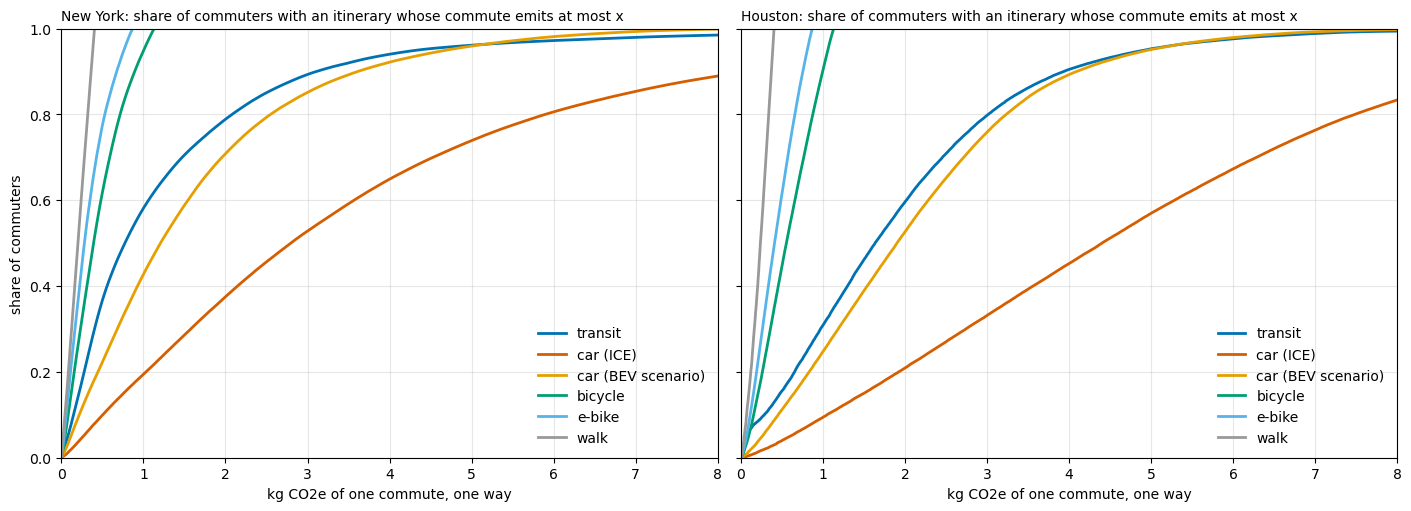

In [6]:
COLOURS = {"transit": "#0072B2", "car": "#D55E00", "car_bev": "#E69F00", "bicycle": "#009E73", "e_bike": "#56B4E9", "walk": "#999999"}
LABELS = {"transit": "transit", "car": f"car ({PARAMETERS['car_vehicle_class']})", "car_bev": "car (BEV scenario)", "bicycle": "bicycle", "e_bike": "e-bike", "walk": "walk"}

figure, axes = plt.subplots(ncols=len(AREAS), figsize=(7 * len(AREAS), 5), layout="constrained", sharey=True)
for axis, (area, table) in zip(np.atleast_1d(axes), commutes.items()):
    for mode in REPORTED_MODES:
        rows = table.loc[(table["mode"] == mode) & table["grams"].notna()]
        if rows.empty:
            continue
        order = np.argsort(rows["grams"].to_numpy())
        grams = rows["grams"].to_numpy()[order]
        share = np.cumsum(rows["workers"].to_numpy()[order]) / rows["workers"].sum()
        axis.plot(grams / 1000, share, color=COLOURS[mode], linewidth=2, label=LABELS[mode])
    axis.set_xlim(0, 8)
    axis.set_ylim(0, 1)
    axis.set_xlabel("kg CO2e of one commute, one way")
    axis.set_title(f"{area}: share of commuters with an itinerary whose commute emits at most x", loc="left", fontsize=10)
    axis.grid(alpha=0.3)
    axis.legend(loc="lower right", frameon=False)
np.atleast_1d(axes)[0].set_ylabel("share of commuters");

## 6. Maps: weekly commuting CO₂e by home tract, New York beside Houston

One figure per mode with the two areas side by side, in the style of the carbon-budgets paper's
city-by-mode maps: the same four weekly classes and colours, white tract edges, no axes, a
shared legend. The value mapped is the median over the tract's residents of their weekly
commuting CO₂e, four return commutes of the one-way grams above, among the residents with an
itinerary. Tracts where fewer than half of the residents have an itinerary are grey, which is
where Houston's transit map and the walking maps mostly fall.

The basemap is Esri's World Gray Canvas, a light grey canvas close to CARTO Positron that serves
tiles without a key. CARTO's own tiles require an API key and stamp anonymous requests with a
watermark; to use them, point `BASEMAP` at a keyed provider as the paper's `basemaps.py` does.
Tiles are cached under `~/.cache/contextily`, and a panel is drawn without its basemap if the
tile server cannot be reached. Each figure is saved in `figures/` at 300 dpi.

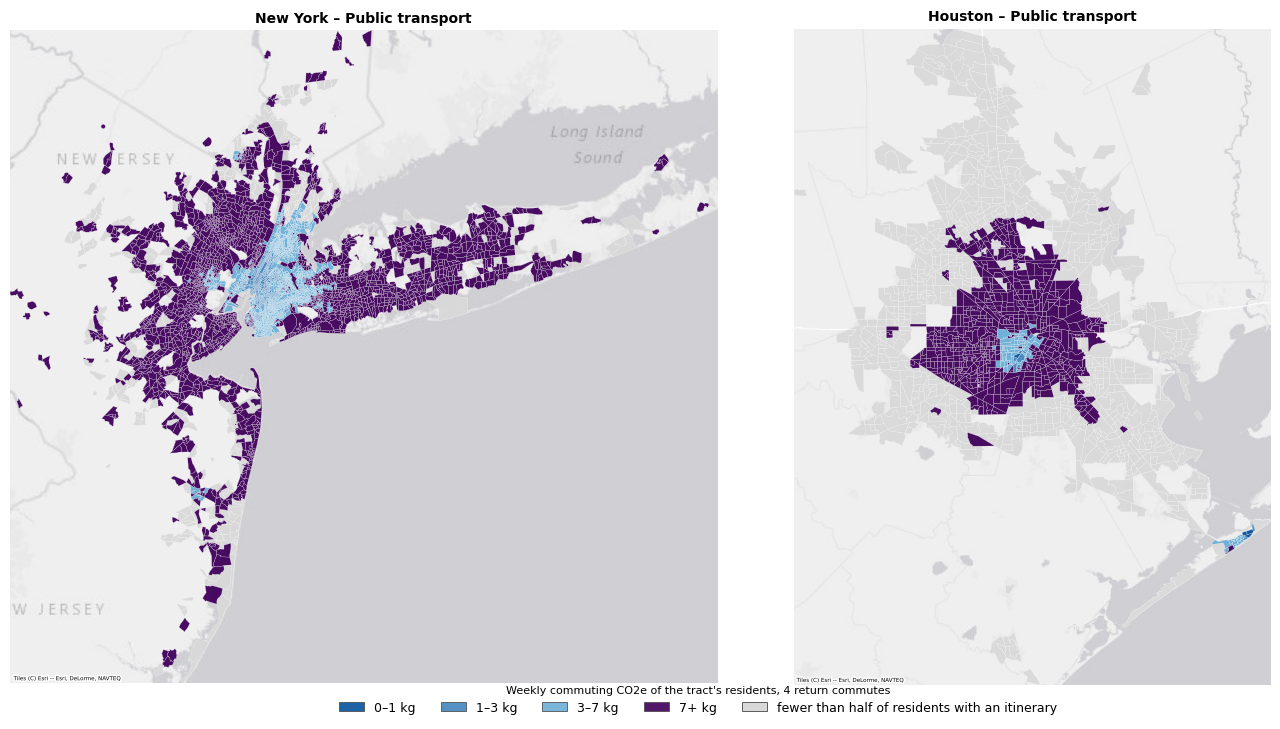

saved figures/05.9-commute-emissions-transit.png


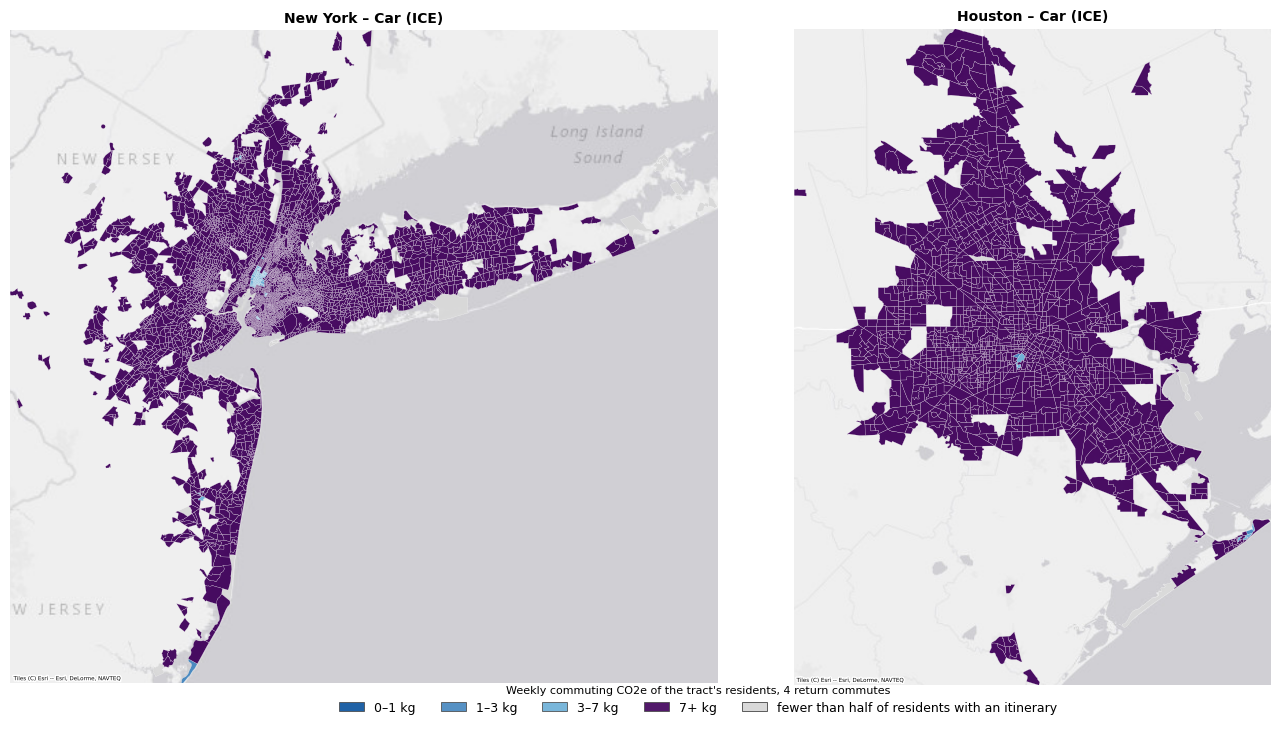

saved figures/05.9-commute-emissions-car.png


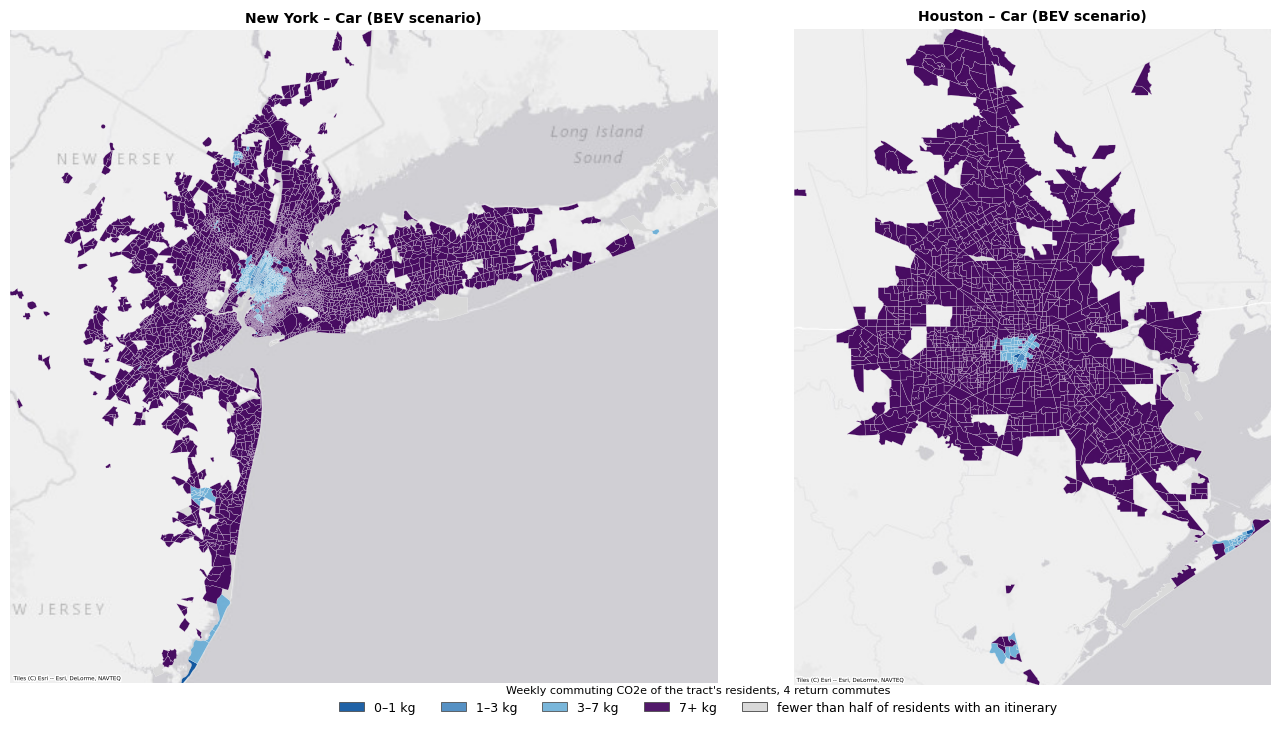

saved figures/05.9-commute-emissions-car_bev.png


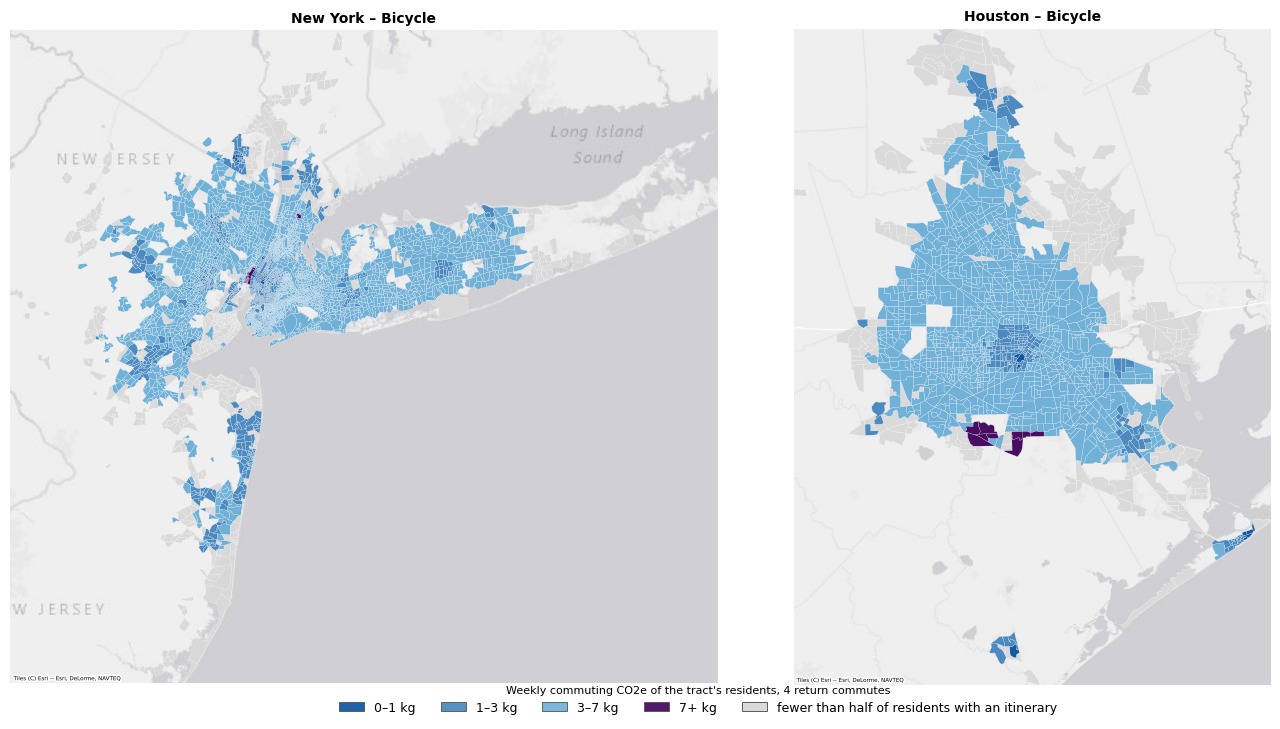

saved figures/05.9-commute-emissions-bicycle.png


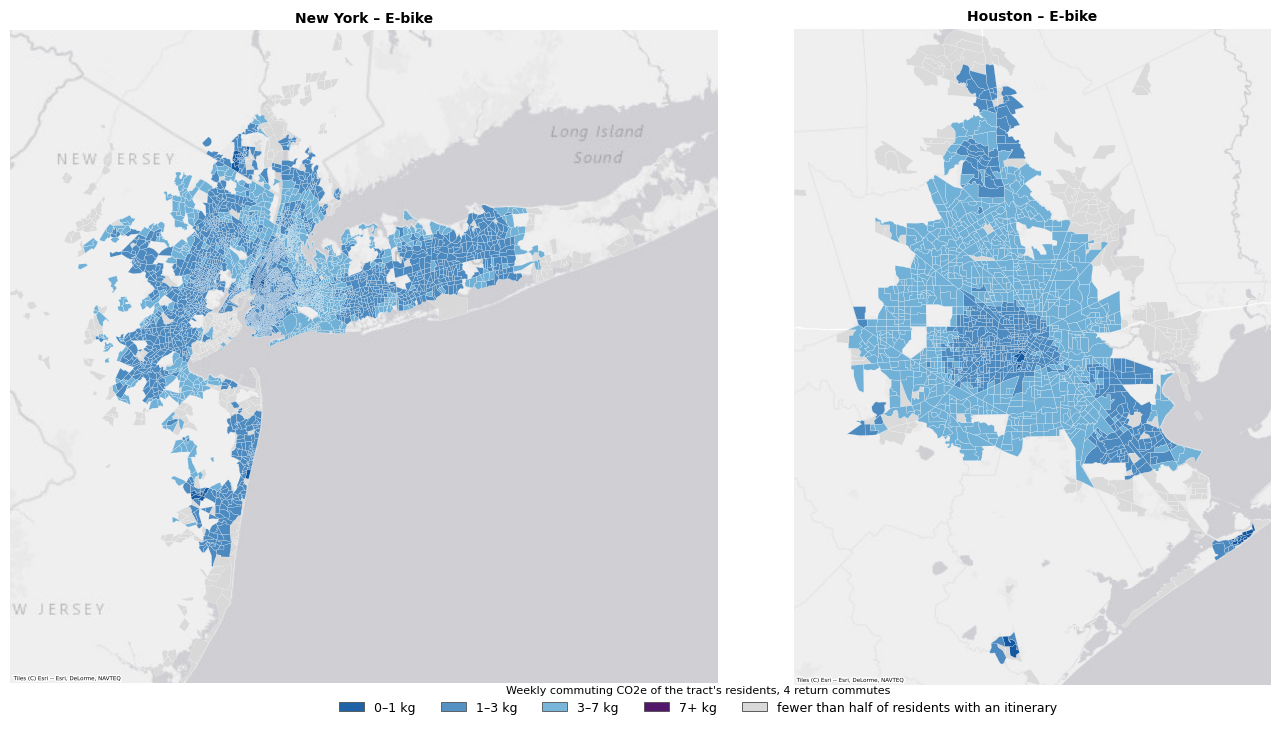

saved figures/05.9-commute-emissions-e_bike.png


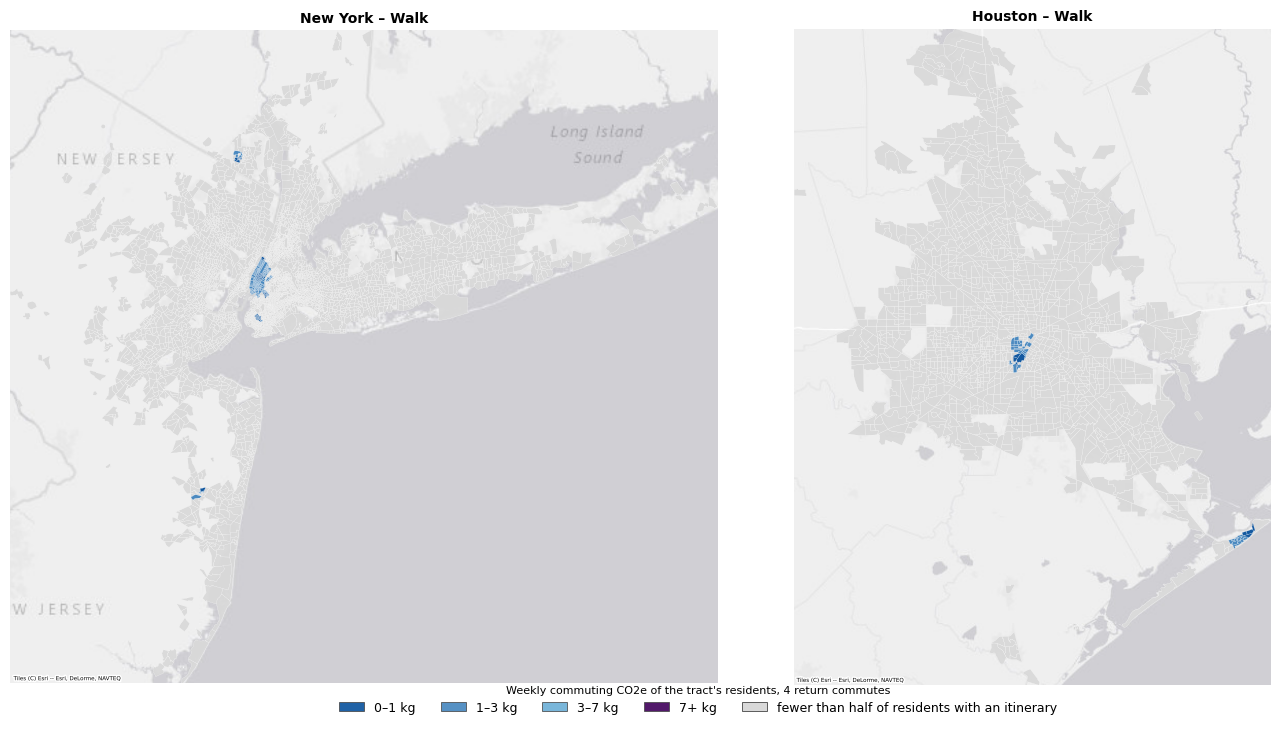

saved figures/05.9-commute-emissions-walk.png
home tracts per weekly class:


0–1 kg  1–3 kg  3–7 kg  7+ kg  \
mode    area                                      
transit New York      38     598    1643   1973   
        Houston        4      10      76    644   
car     New York       1      12     130   4428   
        Houston        0       2       7   1434   
car_bev New York       4     139     665   3763   
        Houston        2       7      71   1363   
bicycle New York      96    1079    2878     18   
        Houston       10     159    1029      9   
e_bike  New York     204    2932    1087      0   
        Houston       20     501     777      0   
walk    New York      82     193       0      0   
        Houston        8      34       0      0   

                  fewer than half of residents with an itinerary  
mode    area                                                      
transit New York                                             337  
        Houston                                              713  
car     New York                                              18  
        Houston                                                4  
car_bev New York                                              18  
        Houston                                                4  
bicycle New York                                             518  
        Houston                                              240  
e_bike  New York                                             366  
        Houston                                              149  
walk    New York                                            4314  
        Houston                                             1405

In [7]:
import contextily as ctx
import matplotlib.patches as mpatches

BASEMAP = ctx.providers.Esri.WorldGrayCanvas
ctx.set_cache_dir(str(Path.home() / ".cache" / "contextily"))
FIGS_DPI = 300

plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 8,
                     "axes.linewidth": 0.6, "svg.fonttype": "none", "pdf.fonttype": 42})

# The paper's weekly classes and colours.
BINS = [0, 1, 3, 7, np.inf]
BIN_LABELS = ["0\u20131 kg", "1\u20133 kg", "3\u20137 kg", "7+ kg"]
BIN_COLOURS = {"0\u20131 kg": "#08519C", "1\u20133 kg": "#4385BE", "3\u20137 kg": "#6BAED6", "7+ kg": "#3F005A"}
NO_ITINERARY = "fewer than half of residents with an itinerary"
NO_ITINERARY_COLOUR = "#d9d9d9"
MODE_TITLES = {"transit": "Public transport", "car": f"Car ({PARAMETERS['car_vehicle_class']})", "car_bev": "Car (BEV scenario)",
               "bicycle": "Bicycle", "e_bike": "E-bike", "walk": "Walk"}
WEEKLY_PER_GRAM = 2 * PARAMETERS["commutes_per_week"] / 1000


def tract_weekly(table, mode):
    # Per home tract: the residents' median weekly kg among those with an itinerary, and the share with one.
    rows = table.loc[table["mode"] == mode]
    residents = rows.groupby("from_id")["workers"].sum()
    reached = rows.loc[rows["grams"].notna()]
    share = reached.groupby("from_id")["workers"].sum().reindex(residents.index, fill_value=0) / residents
    weekly = reached.groupby("from_id").apply(lambda r: weighted_median(r["grams"].to_numpy(), r["workers"].to_numpy()), include_groups=False) * WEEKLY_PER_GRAM
    out = pd.DataFrame({"weekly_kg": weekly.reindex(residents.index), "share_with_itinerary": share})
    out["category"] = pd.cut(out["weekly_kg"], bins=BINS, labels=BIN_LABELS, include_lowest=True).astype(object)
    out.loc[out["share_with_itinerary"] < 0.5, "category"] = NO_ITINERARY
    return out.rename_axis("tract").reset_index()


tract_polygons = {}
for area, spec in AREAS.items():
    polygons = gpd.read_parquet(spec["folder"] / f"tracts-kept-{YEAR}.parquet")[["tract", "geometry"]].to_crs("EPSG:3857")
    polygons["tract"] = polygons["tract"].astype(str)
    tract_polygons[area] = polygons


def draw_panel(axis, area, mode):
    layer = tract_polygons[area].merge(tract_weekly(commutes[area], mode), on="tract", how="left")
    layer["category"] = layer["category"].fillna(NO_ITINERARY)
    for label, colour in [(NO_ITINERARY, NO_ITINERARY_COLOUR)] + list(BIN_COLOURS.items()):
        subset = layer.loc[layer["category"] == label]
        if len(subset):
            subset.plot(ax=axis, color=colour, edgecolor="white", linewidth=0.15, alpha=0.95)
    west, south, east, north = layer.total_bounds
    axis.set_xlim(west, east)
    axis.set_ylim(south, north)
    try:
        ctx.add_basemap(axis, source=BASEMAP, attribution_size=4)
    except Exception as error:
        print(f"{area}, {mode}: basemap not drawn ({type(error).__name__}: {str(error)[:120]})")
    axis.set_xticks([])
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_visible(False)
    axis.set_aspect("equal")
    axis.set_title(f"{area} \u2013 {MODE_TITLES[mode]}", fontsize=10, fontweight="bold", pad=6)
    return layer


handles = [mpatches.Patch(facecolor=BIN_COLOURS[label], edgecolor="#444444", linewidth=0.6, alpha=0.9, label=label) for label in BIN_LABELS]
handles.append(mpatches.Patch(facecolor=NO_ITINERARY_COLOUR, edgecolor="#444444", linewidth=0.6, label=NO_ITINERARY))

class_counts = []
for mode in REPORTED_MODES:
    figure, axes = plt.subplots(ncols=len(AREAS), figsize=(7 * len(AREAS), 7))
    for axis, area in zip(np.atleast_1d(axes), AREAS):
        layer = draw_panel(axis, area, mode)
        counts = layer["category"].value_counts()
        class_counts.append({"mode": mode, "area": area, **{label: int(counts.get(label, 0)) for label in BIN_LABELS + [NO_ITINERARY]}})
    figure.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.04), frameon=False, fontsize=9,
                  title=f"Weekly commuting CO2e of the tract's residents, {PARAMETERS['commutes_per_week']} return commutes")
    figure.tight_layout()
    png = FIGURES / f"05.9-commute-emissions-{mode}.png"
    figure.savefig(png, dpi=FIGS_DPI, bbox_inches="tight")
    plt.show()
    plt.close(figure)
    print(f"saved {png}")

print("home tracts per weekly class:")
pd.DataFrame(class_counts).set_index(["mode", "area"])

## Replicating to another city

1. Run 05.1 and 05.2 for the metro: the LODES flows and the kept tracts.
2. Run 05.3 for it: the street network artifact from the Geofabrik extract, the GTFS feeds through
   transitio, the transit artifact.
3. Run 05.7: the housing-weighted home points and the jobs-weighted work points, snapped.
4. Add the area to `AREAS` in step 1 and run this notebook. The parameter table and the factor
   table document the run; the commute table is the output the comparison notebooks read.

When the US-specific factors are ready, replace the rows in step 2 through cafein's `factors=`
argument for transit (rows by agency and route type) and `street_factors` rows for the car and
cycling modes, set the car occupancy, and route into a fresh `matrices-emissions` folder.